# Transformer Performance Tests

In [1]:
import sys
from pathlib import Path

ROOT = Path().resolve().parents[0]
sys.path.append(str(ROOT))
sys.path.append(str(ROOT / "src" / "data_generation"))
sys.path.append(str(ROOT / "src" / "models"))
sys.path.append(str(ROOT / "src" / "evaluation"))

In [2]:
# Required adding .vscode/settings.json to get highlighting to work!
from room_dataset import RoomDataset, collate_rooms, load_rooms_as_descriptions
from item_encoder import load_aligned_embeddings, load_item_catalog
from transformer import FurnitureEmbeddingPredictor, TransformerEvaluator
from evaluator import LeaveOneOutEvaluator
from baseline_models import ItemContentBaseline, ItemItemCooccurrence, PopularityPrior

import torch, numpy as np, matplotlib.pyplot as plt, pandas as pd
from torch.utils.data import Dataset, DataLoader

In [3]:
# UNLABELED DATA =============================
train_dataset_unlabeled = RoomDataset("train", labeled=False)
val_dataset_unlabeled = RoomDataset("val", labeled=False)
test_dataset_unlabeled = RoomDataset("test", labeled=False)

def make_dataloader_unlabeled(dataset) -> DataLoader:
    return DataLoader(dataset,
            batch_size=32,
            shuffle=True,
            collate_fn=collate_rooms,
        )

train_loader_unlabeled = make_dataloader_unlabeled(train_dataset_unlabeled)
val_loader_unlabeled = make_dataloader_unlabeled(val_dataset_unlabeled)
test_loader_unlabeled = make_dataloader_unlabeled(test_dataset_unlabeled)
print(train_dataset_unlabeled[0].keys())

dict_keys(['embeddings', 'item_ids', 'room_type'])


In [4]:
# LABELED DATA =============================
train_dataset_labeled = RoomDataset("train", labeled=True)
val_dataset_labeled = RoomDataset("val", labeled=True)
test_dataset_labeled = RoomDataset("test", labeled=True)

def collate_rooms_labeled(batch):
    return collate_rooms(batch, labeled=True)

def make_dataloader_labeled(dataset) -> DataLoader:
    return DataLoader(dataset,
            batch_size=32,
            shuffle=True,
            collate_fn=collate_rooms_labeled,
        )

train_loader_labeled = make_dataloader_labeled(train_dataset_labeled)
val_loader_labeled = make_dataloader_labeled(val_dataset_labeled)
test_loader_labeled = make_dataloader_labeled(test_dataset_labeled)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [5]:
model_unlabeled = FurnitureEmbeddingPredictor(nhead=4, num_candidates=5)

try:
    model_unlabeled.load_state_dict(torch.load(str(ROOT/ "notebooks"/ "multi_head_transformer_unlabeled.pt"), weights_only=True))
except FileNotFoundError:
    print("Unlabeled model not found on disk, training...")
    model_unlabeled.fit(train_loader_unlabeled, labeled_data=False, epochs = 5, lr=1e-4, plot_every=10, loss_type="infonce")
    torch.save(model_unlabeled.state_dict(), str(ROOT/ "notebooks"/ "multi_head_transformer_unlabeled.pt"))


model_labeled = FurnitureEmbeddingPredictor(nhead=4, num_candidates=5)
try:
    model_labeled.load_state_dict(torch.load(str(ROOT/ "notebooks"/ "multi_head_transformer_labeled.pt"), weights_only=True))
except FileNotFoundError:
    print("Labeled model not found on disk, training...")
    model_labeled.fit(train_loader_labeled, labeled_data=True, epochs = 5, lr=1e-4, plot_every=10, loss_type="infonce")
    torch.save(model_labeled.state_dict(), str(ROOT/ "notebooks"/ "multi_head_transformer_labeled.pt"))


Loaded instance on device: mps with 5 candidate head(s)
Loaded instance on device: mps with 5 candidate head(s)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/93 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]/opt/anaconda3/envs/ml/lib/python3.13/site-packages/torch/nn/modules/transformer.py:515: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:182.)
  output = torch._nested_tensor_from_mask(
100%|██████████| 5000/5000 [00:37<00:00, 134.26it/s]


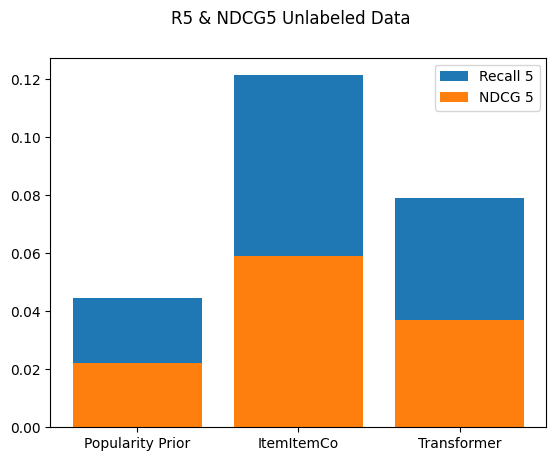

Pop-prior baseline r5: 0.0446, ndcg5: 0.02200652889764159
IIC baseline r5: 0.1214, ndcg5: 0.05894497113253873
Transformer r5: 0.0792, ndcg5: 0.03684714474155464


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/93 [00:00<?, ?it/s]

  0%|          | 8/5000 [00:00<01:09, 71.93it/s]

Did not find embedding for: bedroom
Did not find embedding for: office
Did not find embedding for: living room
Did not find embedding for: dining room
Did not find embedding for: kids room


100%|██████████| 5000/5000 [00:37<00:00, 133.01it/s]


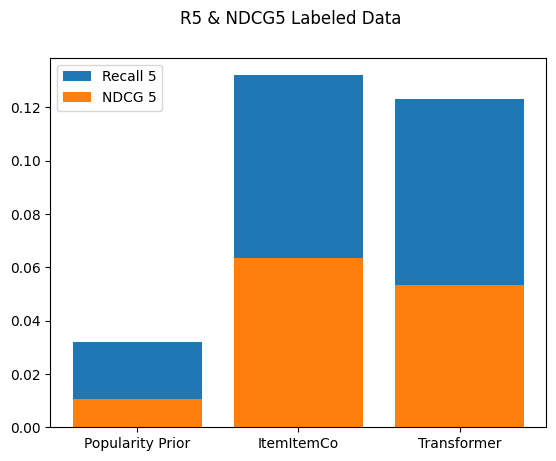

Pop-prior baseline r5: 0.032, ndcg5: 0.010644676664495567
IIC baseline r5: 0.132, ndcg5: 0.06334985916322976
Transformer r5: 0.123, ndcg5: 0.05330894455075205


In [6]:
item_ids, item_descs = load_item_catalog()
item_embeddings = load_aligned_embeddings(item_ids)

rooms_train_l = load_rooms_as_descriptions("train", labeled=True)
rooms_val_l = load_rooms_as_descriptions("val", labeled=True)

rooms_train_ul = load_rooms_as_descriptions("train", labeled=False)
rooms_val_ul = load_rooms_as_descriptions("val", labeled=False)

# ItemContent baseline model currently does not work with labeled data!
#itemContent_model = ItemContentBaseline(item_ids, item_descs, return_descriptions=True)
#5_IC, ndcg5_IC = loo_evaluator.evaluate(itemContent_model, rooms_val, k=10)
#print(f"IC baseline r5: {r5_IC}, ndcg5: {ndcg5_IC}")

def get_and_display_metrics(rooms_train, rooms_val, transformer_model, labeled: bool = False):
    trans_evaluator_model = TransformerEvaluator(transformer_model, item_descriptions=item_descs, aggregation="confidence_weighted_max")
    itemItemCoccurance_model = ItemItemCooccurrence()
    itemItemCoccurance_model.fit(rooms_train)

    popPrior_model = PopularityPrior()
    popPrior_model.fit(rooms_train)

    loo_evaluator = LeaveOneOutEvaluator()

    r5_PP, ndcg5_PP = loo_evaluator.evaluate(popPrior_model, rooms_val, k=10, labeled=labeled)
    r5_IIC, ndcg5_IIC = loo_evaluator.evaluate(itemItemCoccurance_model, rooms_val, k=10, labeled=labeled)
    r5_T, ndcg5_T = loo_evaluator.evaluate(trans_evaluator_model, rooms_val, k=10, labeled=labeled)

    r5s = [r5_PP, r5_IIC, r5_T]
    ndcg5s = [ndcg5_PP, ndcg5_IIC, ndcg5_T]
    labels = ["Popularity Prior", "ItemItemCo", "Transformer"]
    fig, ax = plt.subplots()
    r5_bar = ax.bar(labels, r5s, label="Recall 5")
    ndcg5_bar = ax.bar(labels, ndcg5s, label="NDCG 5")
    if labeled: 
        plt.suptitle("R5 & NDCG5 Labeled Data")
    else:
        plt.suptitle("R5 & NDCG5 Unlabeled Data")
    plt.legend()
    plt.show()

    print(f"Pop-prior baseline r5: {r5_PP}, ndcg5: {ndcg5_PP}")
    print(f"IIC baseline r5: {r5_IIC}, ndcg5: {ndcg5_IIC}")
    print(f"Transformer r5: {r5_T}, ndcg5: {ndcg5_T}")

get_and_display_metrics(rooms_train_ul, rooms_val_ul, model_unlabeled, labeled=False)
get_and_display_metrics(rooms_train_l, rooms_val_l, model_labeled, labeled=True)


In [17]:
# GENERATING ROOMS
import random

trans_evaluator_model = TransformerEvaluator(model_labeled, item_descriptions=item_descs, item_ids=item_ids, item_embeddings=item_embeddings, return_strings=True
                                                , aggregation="confidence_weighted_max")

def strip_items(items: list[str]):
    return [strip_item(item) for item in items]
def strip_item(item: str):
    stripped_left = item.split("Description: ")[-1]
    stripped_right = stripped_left.split(" Designer: ")[0]
    return stripped_right

#test_room = rooms[random.randrange(0, len(rooms))]
test_room = [rooms_val_l[0][0]]
for i in range(10):
    #print(f"Room:\n{strip_items(test_room)}\n")
    prediction = trans_evaluator_model.predict(test_room, k=3)
    test_room.append(prediction[0])
    #print(f"Predictions: \n {strip_items(prediction)}")
    
for item in test_room:
    print(item)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

bedroom
Product series: STUVA / FRITIDS. Category: Beds. Description: Cot with drawers, 60x120 cm. Designer: Ebba Strandmark.
Product series: PLATSA. Category: Wardrobes. Description: Wardrobe, 95-120x42x181 cm. Designer: Ola Wihlborg/IKEA of Sweden.
Product series: ALEX. Category: Chests of drawers & drawer units. Description: Drawer unit with 9 drawers, 36x116 cm. Designer: Johanna Asshoff.
Product series: SVALNÄS. Category: Bookcases & shelving units. Description: Wall-mounted shelf combination, 66x25x176 cm. Designer: Jon Karlsson.
Product series: MICKE. Category: Chests of drawers & drawer units. Description: Drawer unit with drop-file storage, 35x75 cm. Designer: Henrik Preutz.
Product series: SVALNÄS. Category: Bookcases & shelving units. Description: Wall-mounted shelf combination, 193x25x176 cm. Designer: Jon Karlsson.
Product series: PLATSA. Category: Wardrobes. Description: Wardrobe, 195-220x57x241 cm. Designer: IKEA of Sweden/Ola Wihlborg.
Product series: BESTÅ. Category: B